# 1. Introduction & Data Analysis

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")


In [2]:
df = pd.read_csv("datasets/EVChargingStationUsage.csv")
df.head(2)

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,Longitude,Currency,Fee,Ended By,Plug In Event Id,Driver Postal Code,User ID,County,System S/N,Model Number
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/29/2011 20:17,PDT,7/29/2011 23:20,PDT,7/29/2011 23:20,3:03:32,1:54:03,...,-122.160309,USD,0.0,Plug Out at Vehicle,3,95124.0,3284.0,NaN,NaN,NaN
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,7/30/2011 0:00,PDT,7/30/2011 0:02,PDT,7/30/2011 0:02,0:02:06,0:01:54,...,-122.160309,USD,0.0,Customer,4,94301.0,4169.0,NaN,NaN,NaN


## 1.1 Datatypes and missing values

In [3]:
initial_length = len(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 259415 entries, 0 to 259414
Data columns (total 33 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Station Name                     259415 non-null  str    
 1   MAC Address                      259415 non-null  str    
 2   Org Name                         259415 non-null  str    
 3   Start Date                       259415 non-null  str    
 4   Start Time Zone                  259415 non-null  str    
 5   End Date                         259415 non-null  str    
 6   End Time Zone                    259415 non-null  str    
 7   Transaction Date (Pacific Time)  259206 non-null  str    
 8   Total Duration (hh:mm:ss)        259415 non-null  str    
 9   Charging Time (hh:mm:ss)         259415 non-null  str    
 10  Energy (kWh)                     259415 non-null  float64
 11  GHG Savings (kg)                 259415 non-null  float64
 12  Gasoline Savi

In [4]:
# convert date columns to datetime format
df['Start Date'] = pd.to_datetime(df['Start Date'], errors = 'coerce')
df['End Date'] = pd.to_datetime(df['End Date'], errors = 'coerce')
df['Transaction Date (Pacific Time)'] = pd.to_datetime(df['Transaction Date (Pacific Time)'], errors='coerce')

# drop rows with invalid dates
n0 = len(df)
df = df.dropna(subset=['Start Date', 'End Date', 'Transaction Date (Pacific Time)'])
print(f"Dropped {len(df) - n0} rows with invalid or missing dates.")


Dropped -249 rows with invalid or missing dates.


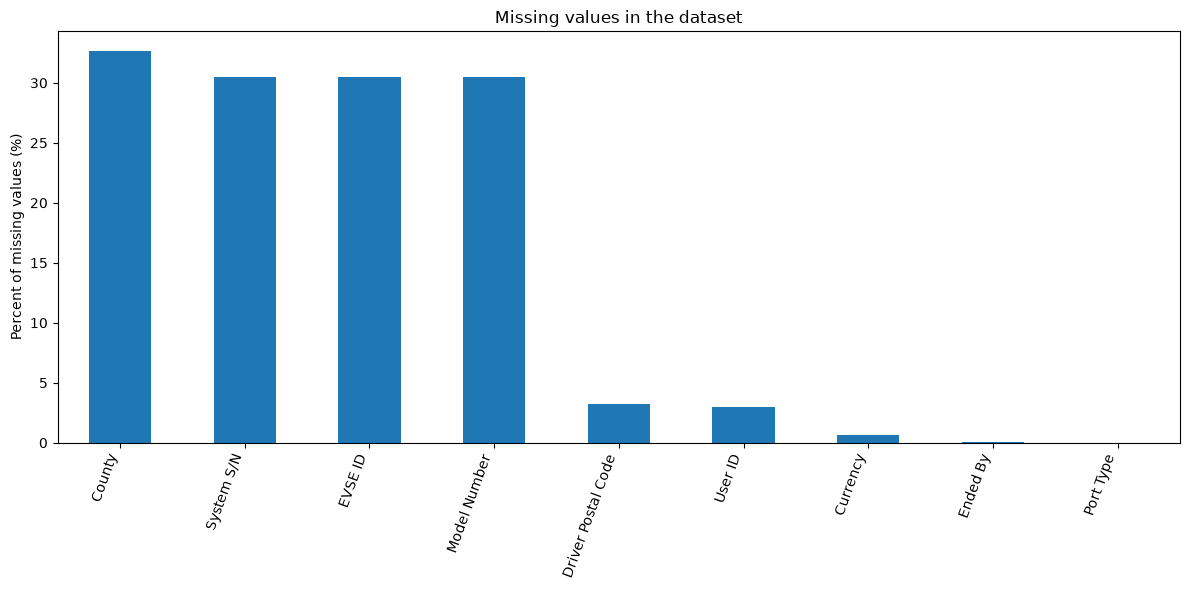

In [5]:
missing = (
    df.isna()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
)

missing = missing[missing > 0]
plt.figure(figsize=(12, 6))
missing.plot(kind="bar")
plt.ylabel("Percent of missing values (%)")
plt.title("Missing values in the dataset")
plt.xticks(rotation=70, ha="right")
plt.tight_layout()
plt.show()

Several missing values - will be imputated by "missing" for categorical features

In [6]:
cat_cols = ['County', 'Model Number', 'User ID', 'Currency', 'Ended By', 'Port Type', 'EVSE ID', 'System S/N', 'Driver Postal Code', 'Postal Code']

for col in cat_cols:
    df[col] = df[col].astype('string').str.strip().fillna('missing')

print(df[cat_cols].isna().sum())

County                0
Model Number          0
User ID               0
Currency              0
Ended By              0
Port Type             0
EVSE ID               0
System S/N            0
Driver Postal Code    0
Postal Code           0
dtype: int64


### 1.1.1 New columns and data cleaning

**Time Zone/Duration checks**

In [7]:
# we have 3 different time zones, so we add a new UTC column to verify the total duration 
print("Unique time zones:",df['Start Time Zone'].unique()) 
offsets = {
    "UTC": 0,
    "PST": -8,
    "PDT": -7
}

df["Start Date UTC"] = (
    df["Start Date"]
    - pd.to_timedelta(df["Start Time Zone"].map(offsets), unit="h")
)

df["End Date UTC"] = (
    df["End Date"]
    - pd.to_timedelta(df["End Time Zone"].map(offsets), unit="h")
)

df[['Start Date', 'Start Time Zone', 'Start Date UTC', 'End Date', 'End Time Zone', 'End Date UTC']].head(2)

Unique time zones: <StringArray>
['PDT', 'PST', 'UTC']
Length: 3, dtype: str


,Start Date,Start Time Zone,Start Date UTC,End Date,End Time Zone,End Date UTC
0,2011-07-29 20:17:00,PDT,2011-07-30 03:17:00,2011-07-29 23:20:00,PDT,2011-07-30 06:20:00
1,2011-07-30 00:00:00,PDT,2011-07-30 07:00:00,2011-07-30 00:02:00,PDT,2011-07-30 07:02:00


Drop columns where start date zone and end date zone are different, as they are likely to be incorrect.

In [8]:
n0 = len(df)
df = df[df['Start Time Zone'] == df['End Time Zone']]
print(f"Dropped {n0 - len(df)} rows where start and end time zones are different.")

Dropped 120 rows where start and end time zones are different.


**Feature engineering**

Add features descibing the start date (year, month, day of week, part of day), as well as transform durations into seconds and hours for easier analysis.

In [10]:
# add year, day of week and month column
df['year'] = df['Start Date'].dt.year
df['month'] = df['Start Date'].dt.month
df['day_of_week'] = df['Start Date'].dt.dayofweek #0 = Monday, 6 = Sunday

# add duration columns in seconds and hours
df["total_duration_sec"] = pd.to_timedelta(df["Total Duration (hh:mm:ss)"], errors="coerce").dt.total_seconds()
df['charging_duration_sec'] = pd.to_timedelta(df["Charging Time (hh:mm:ss)"], errors="coerce").dt.total_seconds()

df['total_duration_hours'] = df['total_duration_sec'] / 3600
df['charging_duration_hours'] = df['charging_duration_sec'] / 3600

# add idle time columns in seconds and hours
df["idle_seconds"] = df["total_duration_sec"] - df["charging_duration_sec"]
df['idle_hours'] = df['idle_seconds'] / 3600

# add time of day
df["start_hour"] = df["Start Date"].dt.hour
conditions = [
    df["start_hour"].between(0, 5),
    df["start_hour"].between(6, 11),
    df["start_hour"].between(12, 17),
    df["start_hour"].between(18, 23)
]

labels = ["Night", "Morning", "Afternoon", "Evening"]

df["time_of_day"] = np.select(
    conditions,
    labels,
    default=None
)


df.head(1)

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,month,day_of_week,total_duration_sec,charging_duration_sec,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,...,7,4,11012.0,6843.0,3.058889,1.900833,4169.0,1.158056,20,Evening


**Tests and removing incosistencies**

In [11]:
# check if we have any rows where the start date is after the end date
print("Number of rows with Start date UTC being later than End Date UTC: ",len(df[df['Start Date UTC']>df['End Date UTC']]))

Number of rows with Start date UTC being later than End Date UTC:  0


In [12]:
# check if the charging duration is longer than the total duration
print("Number of rows with Charging time longer than Total Duration: ",len(df[df['charging_duration_sec']>df['total_duration_sec']]))

n0 = len(df)
df = df[df['charging_duration_sec'] <= df['total_duration_sec']].copy()
print(f"Removed {n0-len(df)} rows with incosistent durations, remaining: {len(df)}")

Number of rows with Charging time longer than Total Duration:  45
Removed 45 rows with incosistent durations, remaining: 259001


Charging time should be in principle lower than total time, therefore if this is not the case we drop the record as it is likely incorrectly calculated.

In [13]:
# checking if Total Durations is equal to End Date - Start Date (with 1 min tolerance in the difference) 
# (just a check to make sure how Total Duration is calculated and if it can be trusted)
total = pd.to_timedelta(df['Total Duration (hh:mm:ss)'])

df['diff_min'] = ((df['End Date UTC'] - df['Start Date UTC']) - total).dt.total_seconds() / 60

TOL = 1.0   # 1 minute tolerance
valid  = df['diff_min'].notna()
within = df['diff_min'].abs() <= TOL

print(f"Missing End Date: {(~valid).sum()}")
print(f"Within Tolerance ±{TOL} min: {within[valid].mean():.2%}")
print(f"Outside Tolerance: {(valid & ~within).sum()}")
print(df.loc[valid & ~within, 'diff_min'].round().value_counts().head(10))

Missing End Date: 0
Within Tolerance ±1.0 min: 99.88%
Outside Tolerance: 308
diff_min
-1.0       79
 1440.0    12
 1.0        8
 5.0        7
 2880.0     5
 1439.0     5
 2.0        4
 6.0        4
 7.0        4
 1441.0     4
Name: count, dtype: int64


In 99% of cases the Total Duration is correctly calculated as End Date - Start Date. Thethe remaining inconsistent cases, will be dropped.

In [14]:
# remove rows with missing End Date or with differences outside the tolerance
n0 = len(df)
df = df[within].copy()       
print(f"Removed {n0 - len(df)} rows ({(n0 - len(df)) / n0:.2%}), remaining: {len(df)}")



Removed 308 rows (0.12%), remaining: 258693


In [15]:
print("---------------------- Final Dataset Size after dropping inconsistent rows:--------------------------- ")
print(len(df))
print("Dropped in total :", initial_length - len(df), "rows, which is", (initial_length - len(df)) / initial_length * 100, "% of the original dataset.")

---------------------- Final Dataset Size after dropping inconsistent rows:--------------------------- 
258693
Dropped in total : 722 rows, which is 0.27831852437214505 % of the original dataset.


We dropped less than 1% of observations during cleaning, which is very little.

In [16]:
df

,Station Name,MAC Address,Org Name,Start Date,Start Time Zone,End Date,End Time Zone,Transaction Date (Pacific Time),Total Duration (hh:mm:ss),Charging Time (hh:mm:ss),...,day_of_week,total_duration_sec,charging_duration_sec,total_duration_hours,charging_duration_hours,idle_seconds,idle_hours,start_hour,time_of_day,diff_min
0,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-29 20:17:00,PDT,2011-07-29 23:20:00,PDT,2011-07-29 23:20:00,3:03:32,1:54:03,...,4,11012.0,6843.0,3.058889,1.900833,4169.0,1.158056,20,Evening,-0.533333
1,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 00:00:00,PDT,2011-07-30 00:02:00,PDT,2011-07-30 00:02:00,0:02:06,0:01:54,...,5,126.0,114.0,0.035000,0.031667,12.0,0.003333,0,Night,-0.100000
2,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 08:16:00,PDT,2011-07-30 12:34:00,PDT,2011-07-30 12:34:00,4:17:32,4:17:28,...,5,15452.0,15448.0,4.292222,4.291111,4.0,0.001111,8,Morning,0.466667
3,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 14:51:00,PDT,2011-07-30 16:55:00,PDT,2011-07-30 16:55:00,2:03:24,2:02:58,...,5,7404.0,7378.0,2.056667,2.049444,26.0,0.007222,14,Afternoon,0.600000
4,PALO ALTO CA / HAMILTON #1,000D:6F00:015A:9D76,City of Palo Alto,2011-07-30 18:51:00,PDT,2011-07-30 20:03:00,PDT,2011-07-30 20:03:00,1:11:24,0:43:54,...,5,4284.0,2634.0,1.190000,0.731667,1650.0,0.458333,18,Evening,0.600000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
259410,PALO ALTO CA / TED THOMPSON #3,0024:B100:0002:9F81,City of Palo Alto,2020-12-31 16:39:00,PST,2020-12-31 17:14:00,PST,2020-12-31 17:16:00,0:35:44,0:35:18,...,3,2144.0,2118.0,0.595556,0.588333,26.0,0.007222,16,Afternoon,-0.733333
259411,PALO ALTO CA / WEBSTER #1,0024:B100:0002:4233,City of Palo Alto,2020-12-31 16:48:00,PST,2020-12-31 20:31:00,PST,2020-12-31 20:32:00,3:43:01,2:14:04,...,3,13381.0,8044.0,3.716944,2.234444,5337.0,1.482500,16,Afternoon,-0.016667
259412,PALO ALTO CA / MPL #4,0024:B100:0003:CD37,City of Palo Alto,2020-12-31 17:28:00,PST,2021-01-01 10:56:00,PST,2021-01-01 10:57:00,17:28:14,5:08:12,...,3,62894.0,18492.0,17.470556,5.136667,44402.0,12.333889,17,Afternoon,-0.233333
259413,PALO ALTO CA / WEBSTER #1,0024:B100:0002:4233,City of Palo Alto,2020-12-31 17:49:00,PST,2020-12-31 21:55:00,PST,2020-12-31 21:56:00,4:05:34,3:53:42,...,3,14734.0,14022.0,4.092778,3.895000,712.0,0.197778,17,Afternoon,0.433333


## 1.2 EDA

In this part we do initial data analysis with a focus on durations, stations and port types.

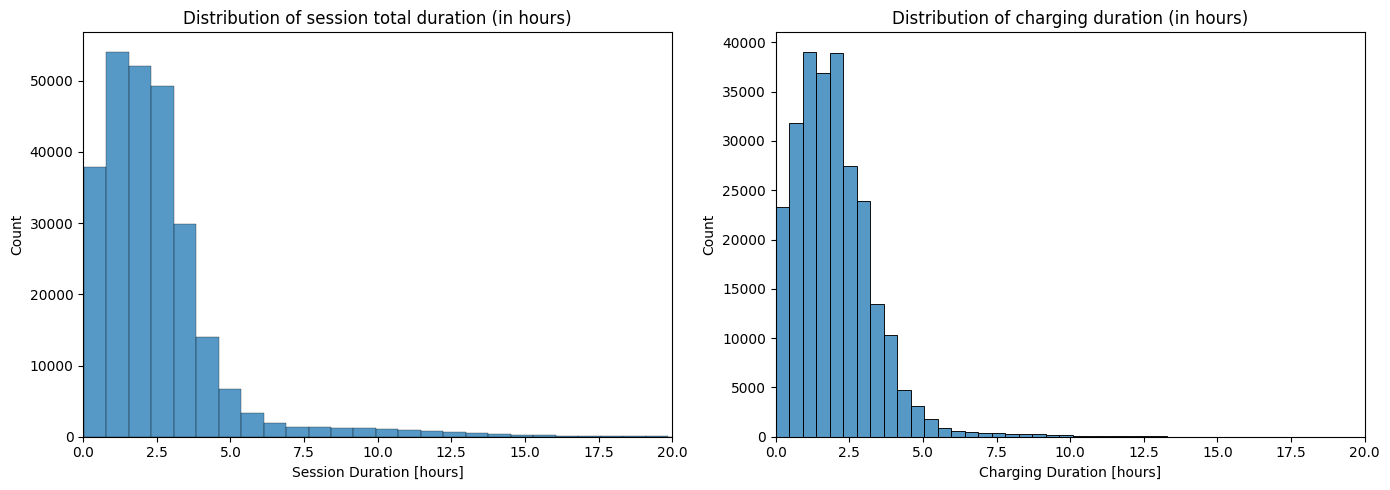

Charging time shorter by at least 15 min: 29.08%


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df, x="total_duration_hours",
    bins=150, ax=axes[0]
)
axes[0].set_title("Distribution of session total duration (in hours)")
axes[0].set_xlabel("Session Duration [hours]")

sns.histplot(
    data=df, x="charging_duration_hours",
    bins=50, ax=axes[1]
)
axes[1].set_title("Distribution of charging duration (in hours)")
axes[1].set_xlabel("Charging Duration [hours]")
axes[0].set_xlim(0, 20)
axes[1].set_xlim(0, 20)
plt.tight_layout()
plt.show()

valid = df[["charging_duration_hours", "total_duration_hours"]].dropna()
diff = valid["total_duration_hours"] - valid["charging_duration_hours"]
percent = (diff >= 15 / 60).mean() * 100

print(f"Charging time shorter by at least 15 min: {percent:.2f}%")

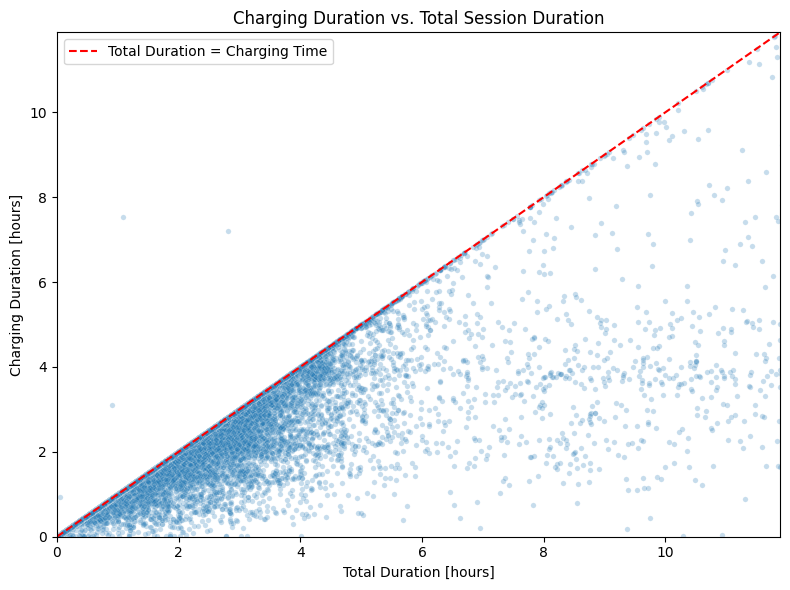

In [18]:
sample = df[
    ["total_duration_hours", "charging_duration_hours"]
].dropna()

if len(sample) > 20000:
    sample = sample.sample(20000, random_state=42)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=sample,
    x="total_duration_hours",
    y="charging_duration_hours",
    alpha=0.25,
    s=15
)

limit = sample[["total_duration_hours", "charging_duration_hours"]].quantile(0.99).max()
plt.plot([0, limit], [0, limit], "--", color="red",
         label="Total Duration = Charging Time")

plt.xlim(0, limit)
plt.ylim(0, limit)
plt.xlabel("Total Duration [hours]")
plt.ylabel("Charging Duration [hours]")
plt.title("Charging Duration vs. Total Session Duration")
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
print("Average total duration (hours):", df["total_duration_hours"].mean())
print("Average charging duration (hours):", df["charging_duration_hours"].mean())

Average total duration (hours): 2.4845659505454125
Average charging duration (hours): 1.998390437700286


Average charging duration is about 2h and total duration about 2.5h.

Idle time = 30 min is equal to 1/4 of the charging time.

## 1.3 Stations analysis 

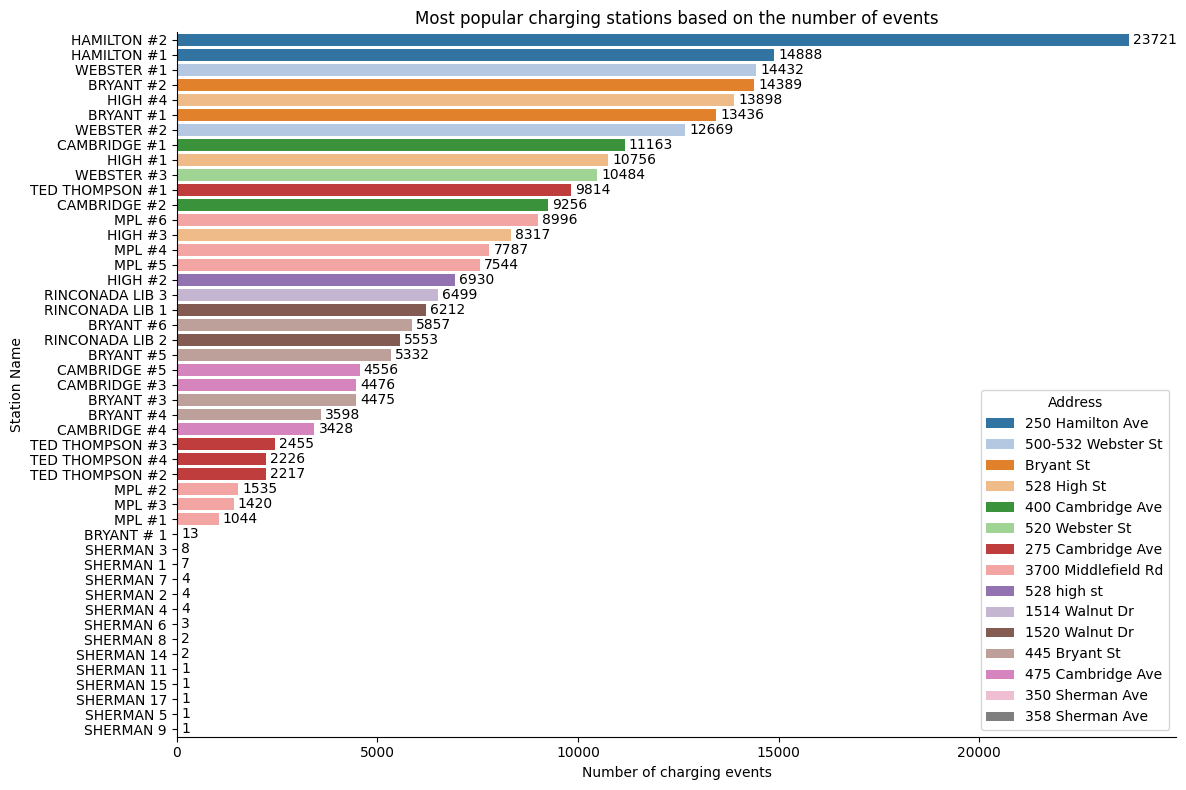

In [20]:
# plot most 'popular' stations based on the number of charging events
station_counts = (
    df.groupby("Station Name")
      .agg(
          n_events=("Station Name", "size"),
          address=("Address 1", "first")
      )
      .sort_values("n_events", ascending=False)
      .reset_index()
)

plt.figure(figsize=(12, 8))
sns.barplot(
    data=station_counts,
    x="n_events",
    y="Station Name",
    hue="address",
    dodge=False,
    palette=sns.color_palette("tab20", n_colors=15)
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

labels = [label.get_text().replace("PALO ALTO CA / ", "") 
          for label in ax.get_yticklabels()]

ax.set_yticklabels(labels)
ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.xlabel("Number of charging events")
plt.ylabel("Station Name")
plt.title("Most popular charging stations based on the number of events")
plt.legend(title="Address")
plt.tight_layout()
plt.show()


In [21]:
top3 = (
    df.groupby(["year", "Station Name"])
      .size()
      .rename("n_events")
      .reset_index()
      .sort_values(["year", "n_events"], ascending=[True, False])
)
top3["rank"] = top3.groupby("year").cumcount() + 1
top3 = top3[top3["rank"] <= 3]
top3["Station Name"] = top3["Station Name"].str.replace("PALO ALTO CA / ", "", regex=False)
table = top3.pivot(index="year", columns="rank", values=["Station Name", "n_events"])
table.columns = [f"{'Station' if a == 'Station Name' else 'Events'} #{b}" for a, b in table.columns]
table = table[[f"{c} #{i}" for i in (1, 2, 3) for c in ("Station", "Events")]]   # parami: stacja, liczba

display(table)

,Station #1,Events #1,Station #2,Events #2,Station #3,Events #3
year,,,,,,
2011,HAMILTON #1,457,HAMILTON #2,396,HIGH #4,172
2012,HAMILTON #1,1407,HAMILTON #2,1371,BRYANT #2,1358
2013,BRYANT #2,2160,BRYANT #1,2114,HAMILTON #1,1988
2014,BRYANT #1,2505,BRYANT #2,2491,HIGH #4,2064
2015,BRYANT #2,2594,BRYANT #1,2412,HAMILTON #2,2061
2016,HAMILTON #2,3749,WEBSTER #1,3489,WEBSTER #2,3397
2017,HAMILTON #2,3513,WEBSTER #1,3191,CAMBRIDGE #1,3017
2018,HAMILTON #2,3429,WEBSTER #1,2644,WEBSTER #2,2157
2019,HAMILTON #2,3734,WEBSTER #1,2584,HIGH #3,2376


Hamilton, Bryant, Webster - the most overall events and leading in all years. Sherman - almost unused.

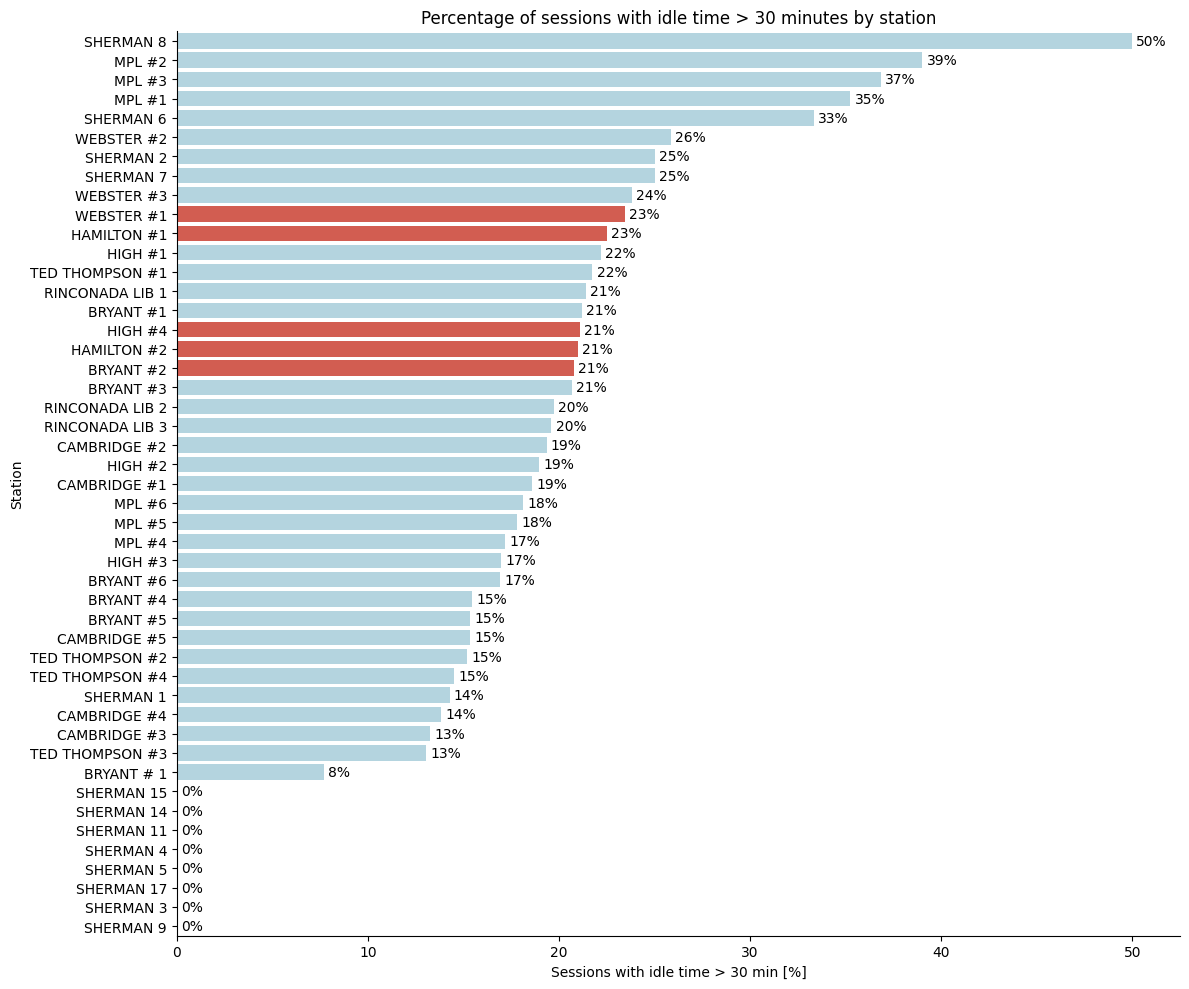

In [22]:
# plot the percentage of sessions with idle time greater than 20 minutes for each station
# highlighted most popular stations in red
idle_pct = (
    df.groupby("Station Name")["idle_hours"]
    .agg(
        total="count",
        above_30min=lambda x: (x > 30 / 60).sum()
    )
    .assign(percent=lambda x: 100 * x["above_30min"] / x["total"])
    .sort_values("percent", ascending=False)
)

highlight_stations = [
    "PALO ALTO CA / HAMILTON #1",
    "PALO ALTO CA / WEBSTER #1",
    "PALO ALTO CA / HAMILTON #2",
    "PALO ALTO CA / BRYANT #2",
    "PALO ALTO CA / HIGH #4",
]

plot_data = idle_pct.reset_index()
plot_data["color"] = plot_data["Station Name"].apply(
    lambda x: "Highlight" if x in highlight_stations else "Other"
)

palette = {"Highlight": "#e74c3c", "Other": "lightblue"}

fig, ax = plt.subplots(figsize=(12, 10))

sns.barplot(
    data=plot_data,
    x="percent",
    y="Station Name",
    hue="color",
    palette=palette,
    dodge=False,
    legend=False,
    ax=ax
)
ax = plt.gca()
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f%%", padding=3)
labels = [
    label.get_text().replace("PALO ALTO CA / ", "")
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

ax.set_xlabel("Sessions with idle time > 30 min [%]")
ax.set_ylabel("Station")
ax.set_title("Percentage of sessions with idle time > 30 minutes by station")

sns.despine()
plt.tight_layout()
plt.show()

Sherman/MPL with a high percentage (is also due to a low number of events). The top 5 most popular stations have the % of events with idle time>30 min at around 20%, which is quite high.

## 1.4 Port type analysis

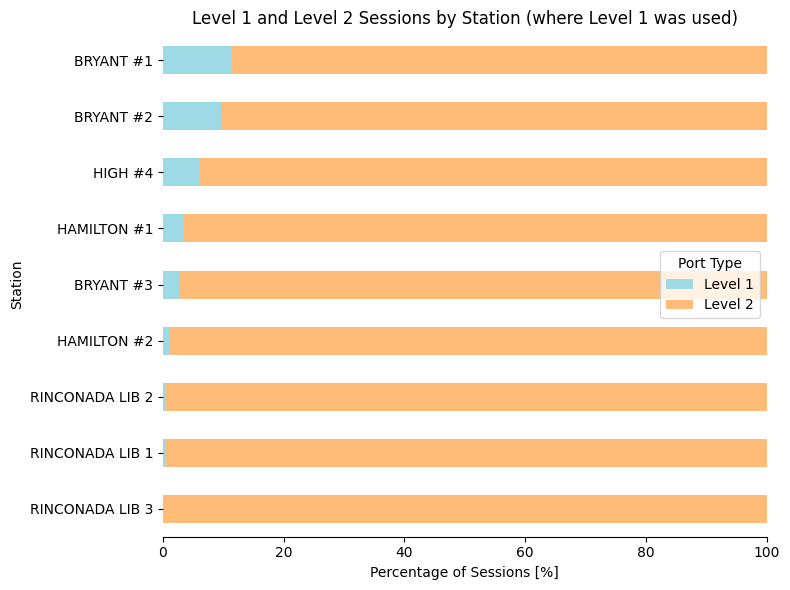

In [23]:
# Stations where at least one Level 1 session occurred
stations_level1 = df.loc[
    df["Port Type"] == "Level 1", "Station Name"
].unique()

df_levels = df[
    df["Station Name"].isin(stations_level1)
    & df["Port Type"].isin(["Level 1", "Level 2"])
].copy()

level_pct = pd.crosstab(
    df_levels["Station Name"],
    df_levels["Port Type"],
    normalize="index"
) * 100

level_pct = level_pct.reindex(
    columns=["Level 1", "Level 2"], fill_value=0
).sort_values("Level 2", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))

level_pct.plot(
    kind="barh",
    stacked=True,
    color=["#9edae5", "#ffbb78"],
    ax=ax
)

labels = [
    label.get_text().replace("PALO ALTO CA / ", "")
    for label in ax.get_yticklabels()
]
ax.set_yticklabels(labels)

ax.set_xlabel("Percentage of Sessions [%]")
ax.set_ylabel("Station")
ax.set_title("Level 1 and Level 2 Sessions by Station (where Level 1 was used)")
ax.legend(title="Port Type")
ax.set_xlim(0, 100)


sns.despine(ax=ax)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.show()

Port Type = Level 1 was only used at 9 stations, and the % of events with Level1 are less than 20% on each station.

## 1.5 Durations deeper-dive

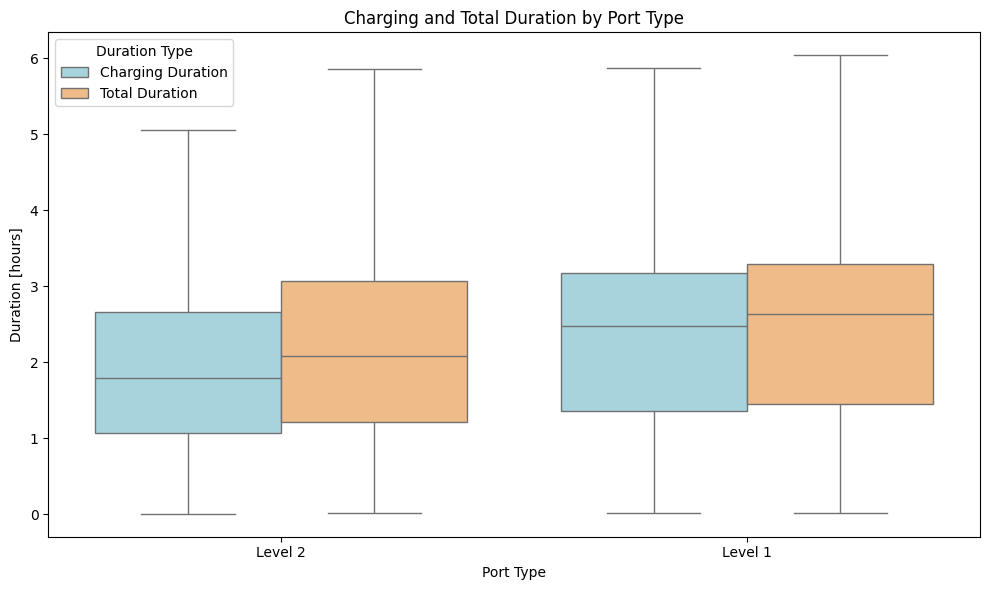

In [24]:
# plot the distribution of charging/total duration for Level 1 and Level 2 sessions
df_plot = df_levels.melt(
    id_vars="Port Type",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Duration"
})

plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_plot,
    x="Port Type",
    y="Duration [hours]",
    hue="Duration Type",
    showfliers=False,
    palette=["#9edae5", "#ffbb78"]
)

plt.xlabel("Port Type")
plt.ylabel("Duration [hours]")
plt.title("Charging and Total Duration by Port Type")
plt.legend(title="Duration Type")
plt.tight_layout()
plt.show()

Level 1 is a slower port type; the differences in total duration vs charging duration are bigger for Level2.

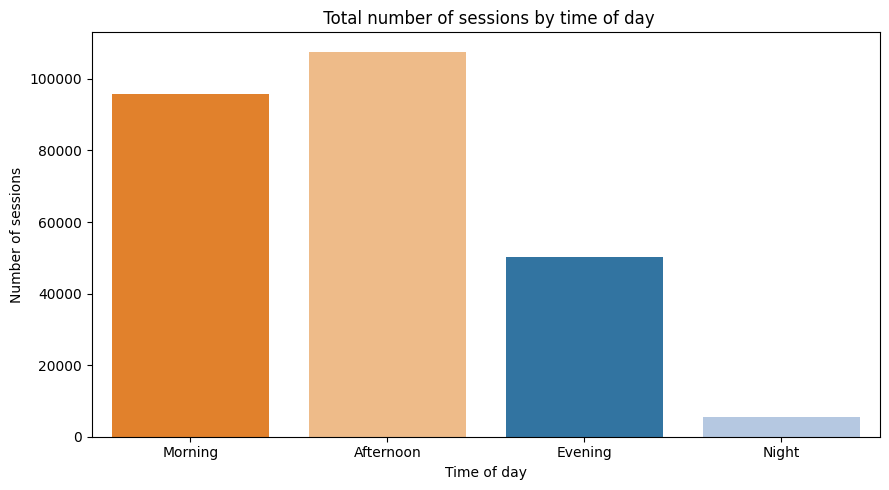

In [25]:
# plot the number of sessions by time of day
order = [ "Morning", "Afternoon", "Evening", "Night"]

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="time_of_day",
    order=order,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by time of day")
plt.tight_layout()
plt.show()

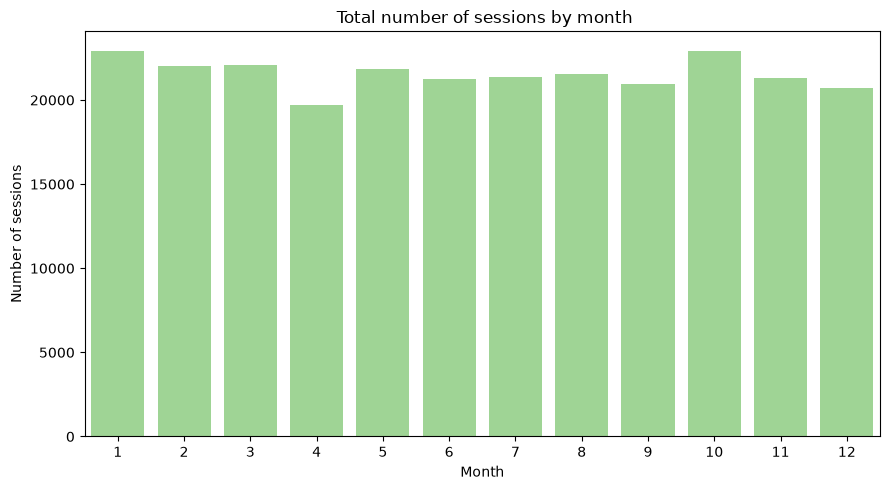

In [26]:
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="month",
    color="#98df8a",
    legend=False
)

plt.xlabel("Month")
plt.ylabel("Number of sessions")
plt.title(" Total number of sessions by month")
plt.tight_layout()
plt.show()

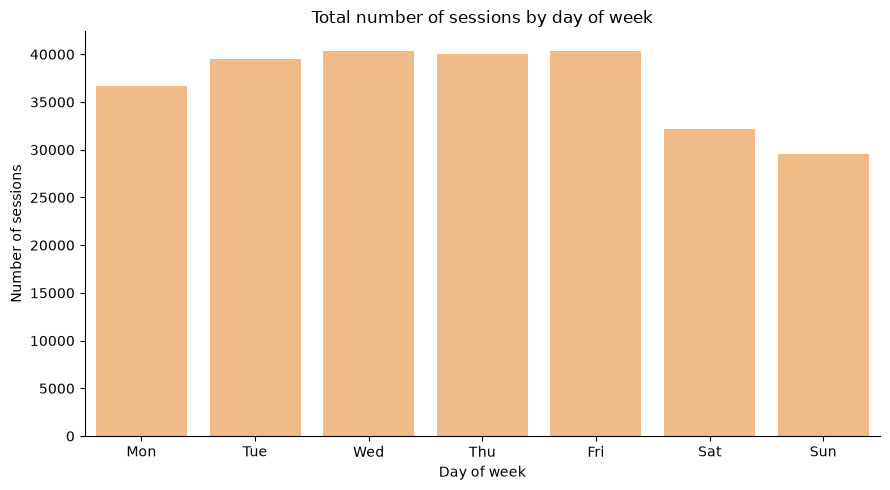

In [27]:
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

plt.figure(figsize=(9, 5))
ax = sns.countplot(
    data=df,
    x="day_of_week",
    order=range(7),         
    color="#ffbb78"
)

ax.set_xticks(range(7))
ax.set_xticklabels(day_names)
ax.spines[["top", "right"]].set_visible(False)

plt.xlabel("Day of week")
plt.ylabel("Number of sessions")
plt.title("Total number of sessions by day of week")
plt.tight_layout()
plt.show()

The highest charging traffic happens in the morning and afternoon and on the weekdays.

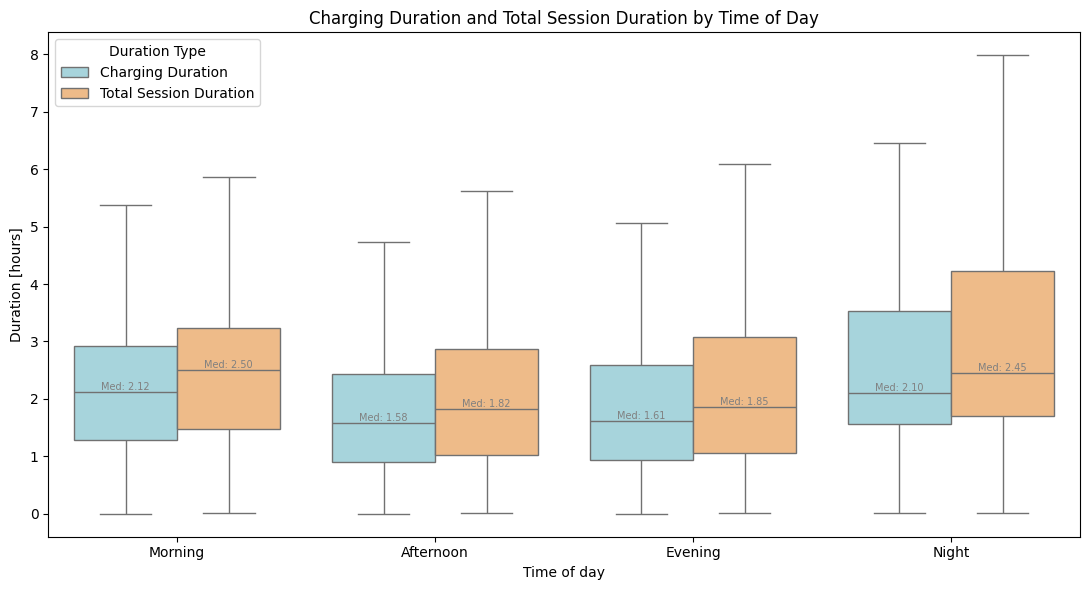

In [28]:
# plot the distribution of charging / total duration for each time of day
df_plot = df.melt(
    id_vars="time_of_day",
    value_vars=["charging_duration_hours", "total_duration_hours"],
    var_name="Duration Type",
    value_name="Duration [hours]"
)

df_plot["Duration Type"] = df_plot["Duration Type"].map({
    "charging_duration_hours": "Charging Duration",
    "total_duration_hours": "Total Session Duration"
})

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df_plot,
    x="time_of_day",
    y="Duration [hours]",
    order=order,
    hue="Duration Type",
    palette=["#9edae5", "#ffbb78"],
    showfliers=False
)

plt.xlabel("Time of day")
plt.ylabel("Duration [hours]")
plt.title("Charging Duration and Total Session Duration by Time of Day")
plt.legend(title="Duration Type")
# Add Q1, median and Q3 labels
stats = (
    df_plot.groupby(["time_of_day", "Duration Type"])["Duration [hours]"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
)
n_hue = 2
offsets = [-0.2, 0.2]

for i, tod in enumerate(order):
    for j, duration_type in enumerate(["Charging Duration", "Total Session Duration"]):
        if (tod, duration_type) not in stats.index:
            continue

        q1, median, q3 = stats.loc[(tod, duration_type)].values
        x = i + offsets[j]

        ax = plt.gca()
        ax.text(x, median, f"Med: {median:.2f}",
                ha="center", va="bottom", fontsize=7, color='gray')
plt.tight_layout()
plt.show()

The highest charging and total times are observed in the morning and night. At night there are some outliers reaching up to 8h of total duration (the spread is also the greatest at night). The biggest difference in Medians between charging and total time is 0.38 (Mornings).

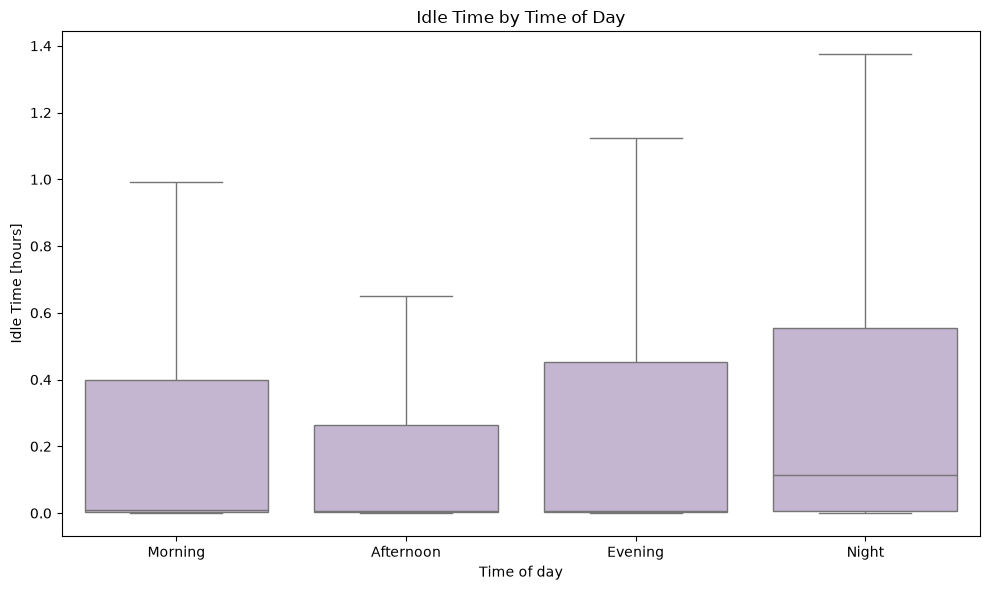

In [29]:
# Idle time analysis by time of day
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df[df["idle_hours"] >= 0],
    x="time_of_day",
    y="idle_hours",
    order=order,
    color="#c5b0d5",
    showfliers=False,
    legend=False
)

plt.xlabel("Time of day")
plt.ylabel("Idle Time [hours]")
plt.title("Idle Time by Time of Day")
plt.tight_layout()
plt.show()

At night idle times are the highest (up to 1.4h) with median areound 0.1h

# 2. Mandatory Component

## 2.1 (Task 1): Cluster the users based on usage patterns

## 2.2 (Task 2): Build a prediction model for energy consumption of charging stations

# 3. Exploratory Component

# 4. Conclusions

# 5. Individual contributions


| Contributor | Percentage | Concretely |
| -------- | ------- | ------- |
| Katarzyna (s123456)  | 100%    | Introductive data analysis |
| Michal (s123456) | 100%     | |
| Frederikke (s123456)   | 100%    | |
| Frederik (s234644)   | 100%    | |